# Floe Splitting Methods

Sea ice floe detection in the IFT workflow uses a binarize -> split -> evaluate workflow. This notebook demonstrates and tests an improvement to the Buckley et al. erosion-expansion algorithm, incorporating erosion-propagation methods and filtering. 

The original algorithm operates on a binary ice/water mask using as structure element $SE$. Beginning with $n=$itermax$=8$, the mask is eroded $n$ times. Connected components are labeled, then dilated $n$ times. A minimum area criterion is applied, then the watershed algorithm is used to expand the labeled components to the original ice/water mask boundary. Labeled pixels are then removed from the binary ice/water mask, and the procedure is repeated with $n-1$ erosion/dilation steps. This algorithm was validated for estimation of the floe size distribution in the Beaufort Sea. 

We update the Buckley et al. 2024 erosion-expansion algorithm (BEE) to address segmentation errors which affect sea ice floe tracking while having only minimal effects on FSD estimation. The algorithm has been re-implemented in Julia.
1. Size thresholds in the original algorithm were applied after dilation. We examined the error in re-grown sea ice floe size using a sample of manually labeled floes. We computed the area (boundary?) error after n erosions and n expansions, and 



In [ ]:
using Pkg
Pkg.activate("../scripts/calval")
using IceFloeTracker
using Images
using DataFrames
using CSVFiles
using CairoMakie
using StatsBase
import IceFloeTracker.Morphology: fill_holes!


In [24]:
# Load data
dataset = Watkins2026Dataset(;
    url="https://github.com/danielmwatkins/ice-floe-validation-dataset/",
    ref="v0.2",
    cache_dir="/tmp/Watkins2026",
    metadata_path="data/validation_dataset/validation_dataset.csv",
)

#### Run this to use the previously defined test/train split ####
prior_data = DataFrame(load("../data/train_test_split.csv"))
dataset.info[:, :training_sample] = parse.(Bool, prior_data[:, :training_sample])
dataset.info[:, :testing_sample] = parse.(Bool, prior_data[:, :testing_sample])
train_cases = filter(c -> c.training_sample, dataset) 
test_cases = filter(c -> c.testing_sample, dataset);

train_cases.info[:, :lookup_index] = 1:nrow(train_cases.info)
test_cases.info[:, :lookup_index] = 1:nrow(test_cases.info);


In [27]:
size(img)

(1961, 1863)

In [34]:
# Testing version -- download had issues.
img = load("../data/beaufort_sea-2017-06-10.tiff")[1:1400, 1:1700]
binary_img = binarize(Gray.(img), AdaptiveThreshold(; window_size=399, percentage=0));

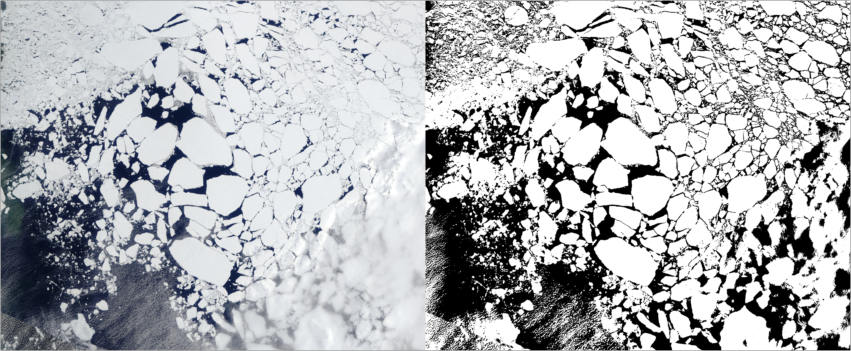

In [35]:
mosaicview(img, binary_img, nrow=1)

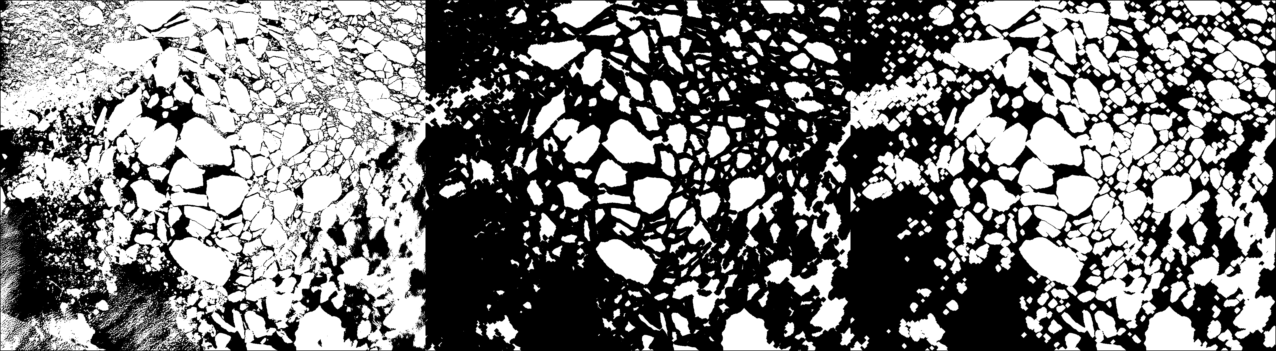

In [36]:
# Run example from Buckley et al. 2024
strel=strel_diamond((3,3))
iters=8
eroded_ice_mask = copy(binary_img)
foreach(_ -> erode!(eroded_ice_mask, copy(eroded_ice_mask), strel), 1:iters)
fill_holes!(eroded_ice_mask, copy(eroded_ice_mask), strel_diamond((3,3)))
markers = label_components(eroded_ice_mask) .+ 1
dilated_ice_mask = copy(eroded_ice_mask)
foreach(_ -> dilate!(dilated_ice_mask, copy(dilated_ice_mask), strel), 1:iters)

mosaicview(binary_img, Gray.(eroded_ice_mask), Gray.(dilated_ice_mask), nrow=1)

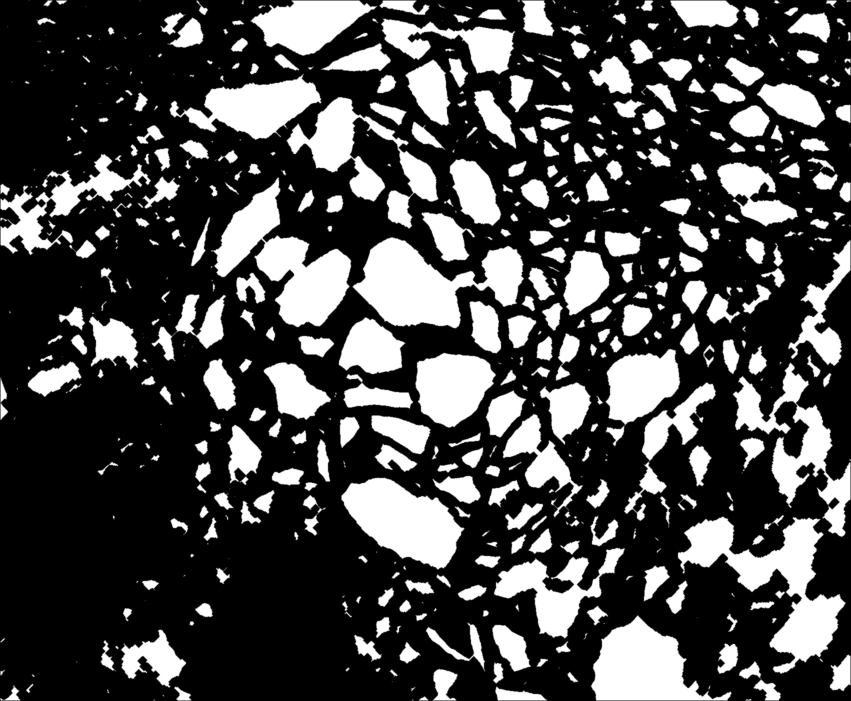

In [37]:
Gray.(eroded_ice_mask)

By repeating the erosion operation with the diamond structuring element, we run into the issue that floes remain connected by thin diagonal lines.

In [9]:
# An option: Apply opening with a different-shaped structuring element
# with size depending on the number of iterations. This method results in 
# removing the small pieces, which can be a problem for the last stages of 
# re-growing the image.
# opened_markers = opening(eroded_ice_mask, strel_disk(8))

In [73]:
# ebseg python code
import IceFloeTracker.Morphology: fill_holes

"""

EE method from Buckley et al. 2024

"""
function erosion_expansion(
        gray_img, # image to use in the watershed transformation
        binary_img; # bitmatrix where ice is marked true
        itmin=1, # minimum number of iterations
        itmax=8, # maximum number of iterations
        step=1, # spacing between iterations
        strel=strel_diamond((3,3)),
        minimum_area=16,
        )

    input = copy(binary_img)
    output = zeros(Int64, size(binary_img))
    label_offset = 0
    intermediate = []
    for iters in itmax:-step:itmin
        eroded_ice_mask = copy(binary_img)

        # Note that copy is needed for in-place morphological operations, since
        # the in-place operation will delete the source image along the way.
        
        foreach(_ -> erode!(eroded_ice_mask, copy(eroded_ice_mask), strel), 1:iters)
        fill_holes!(eroded_ice_mask, copy(eroded_ice_mask), strel_diamond((3,3)))
        markers = label_components(eroded_ice_mask) .+ 1
        dilated_ice_mask = copy(eroded_ice_mask)
        foreach(_ -> dilate!(dilated_ice_mask, copy(dilated_ice_mask), strel), 1:iters)

        # Select the pixels between the dilated and the eroded sections.
        # These are where we'll re-grow floes.
        # The phrasing "unknown" is based on the CV2 watershed description
        # (e.g. https://docs.opencv.org/4.13.0/d3/db4/tutorial_py_watershed.html)
        # Setting the background to 1 helps keep it separate at the end.
        
        unknown = copy(dilated_ice_mask)
        unknown[eroded_ice_mask .> 0] .= 0
        markers[unknown .> 0] .= 0
        
        # Dilating the markers replaces values with the maximum in the neighborhood,
        # which can have surprising results with randomly-labeled data.
        foreach(_ -> dilate!(markers, copy(markers), strel), 1:iters)
            
        # Use the watershed transformation to recover some detail of floe edges
        watershed_labels = labels_map(watershed(complement.(gray_img), markers))
        watershed_labels .-= 1
        
        # Set anything originally classified as water to background
        watershed_labels[binary_img .== 0] .= 0
        
        # Clear objects intersecting the land mask (TBD - no land in this image)

        # Clear objects where we've already got output labels
        watershed_labels[output .> 0] .= 0

        # Re-label since regions often are split up at this stage
        watershed_labels .= label_components(watershed_labels)
        push!(intermediate, copy(watershed_labels))
        # Remove small segments
        # Check reasoning for the iters minimum area
        remove_small_segments!(watershed_labels, maximum([minimum_area, iters^4]))

        # Input for next stage:
        # backround in the watershed, positive in the ice mask, positive at beginning of round
        input .= (watershed_labels .== 0) .&& (input .> 0) .&& (binary_img .> 0)

        # Update the output
        new_label_mask = watershed_labels .> 0
        output[new_label_mask] .= watershed_labels[new_label_mask] .+ label_offset
        label_offset = maximum(output)
    end
    output .= label_components(output)
    
    # add min brightness step (TBD)
    
    return (output=output, intermediate=intermediate)
end

erosion_expansion

The erosion expansion method seems to me to be really effective for some cases but to need some work still for other cases. It is fast, and is reasonably easy to understand. The dist-morph-split method is based on the idea of using the distance transform rather than using erosion, and carrying out opening and hole-filling at each level. Then, labeling and re-growing. It's a very similar structure, actually. The biggest difference is in the approach of "zeroing out" the large floes, then looking for the smaller ones in the residual. The issues I'm seeing are that the floes with longer than 8 pixels will never be separated, and the method doesn't have a way to identify these cases.

The dist-morph-split computes the distance matrix, then for each integer distance, we perform morphological opening and filling, label components, and decide whether to move up to the next level. It isn't perfect, it still splits floes that shouldn't be split. It uses the expand labels function which computes the distance transform again.


  1.529518 seconds (162.68 k allocations: 1.753 GiB, 47.21% gc time)


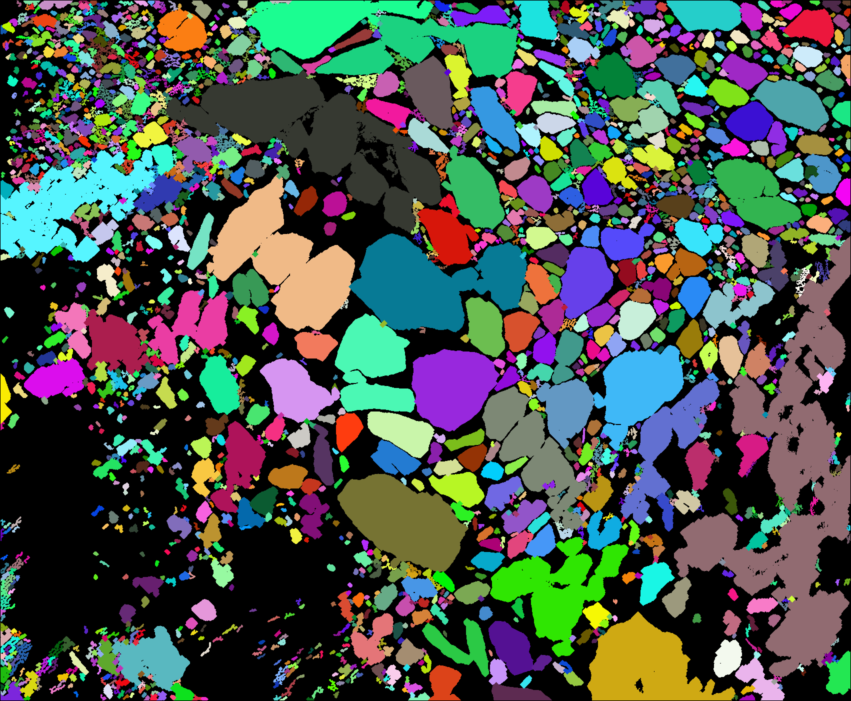

In [128]:
@time begin
    test = erosion_expansion(Gray.(img), binary_img; 
        strel=strel_diamond((3,3)), step=1, itmax=6, minimum_area=64);
end
view_seg_random(SegmentedImage(img, test.output))

Proposed cleanup methods:
1. Filtering (minimum brightness -- hard threshold)
2. Comparison of distance transform to floe area; select individual floes to recompute watershed on subset, using local maxima.
3. Check the floe probability for combinations of neighboring objects
4. Object-wise fill holes

In [109]:
# Which pieces would be rejected?
maxiters = 12
test = erosion_expansion(Gray.(img), binary_img; 
        strel=strel_diamond((3,3)), step=1, itmax=maxiters);

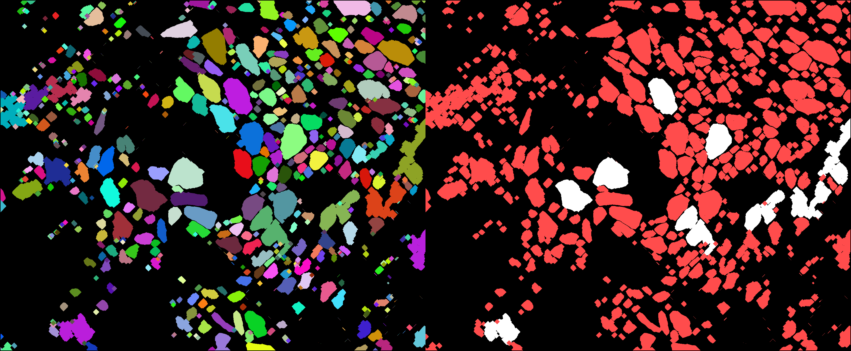

In [113]:
iters = 10
threshold = iters^4
index = maxiters - iters + 1
watershed_result = test.intermediate[index]
eroded_result = watershed_result .> 0
foreach(_-> erode!(eroded_result, copy(eroded_result), strel_diamond((3,3))), 1:8)

remaining_labels = copy(watershed_result)
remove_small_segments!(remaining_labels, threshold)
vis = RGB.(watershed_result .> 0)
vis[watershed_result .> 0] .= RGB(1, 0.3, 0.3)
vis[remaining_labels .> 0] .= RGB(1, 1, 1)

mosaicview(
    #Gray.(eroded_result), 
    view_seg_random(SegmentedImage(img, watershed_result)),
    vis,
    nrow=1
)

In [121]:
imgs = []
for iters in 12:-1:1
    threshold = iters^4
    index = maxiters - iters + 1
    watershed_result = test.intermediate[index]
    eroded_result = watershed_result .> 0
    foreach(_-> erode!(eroded_result, copy(eroded_result), strel_diamond((3,3))), 1:8)
    
    remaining_labels = copy(watershed_result)
    remove_small_segments!(remaining_labels, maximum([16, threshold]))
    vis = RGB.(watershed_result .> 0)
    vis[watershed_result .> 0] .= RGB(1, 0.3, 0.3)
    vis[remaining_labels .> 0] .= RGB(1, 1, 1)
    push!(imgs, vis)
end

save("../figures/ee_method_12iters.png", mosaicview(
    imgs...,
    nrow=4,
        npad=10,
        rowmajor=true,
    fillvalue=RGB(0.8)
))

With 8 iterations, the threshold removes any item smaller than 4096 pixels.

In [98]:
threshold^0.5

64.0

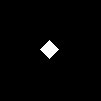

In [102]:
init = zeros(Int64, (101,101))
init[50,50] = 1
foreach(_ -> dilate!(init, copy(init), strel), 1:iters+1)
Gray.(init)


In [103]:
sum(init)

181

In [53]:
df = regionprops_table(test.output; properties=[:area, :circularity, :solidity]);

In [48]:
using Plots

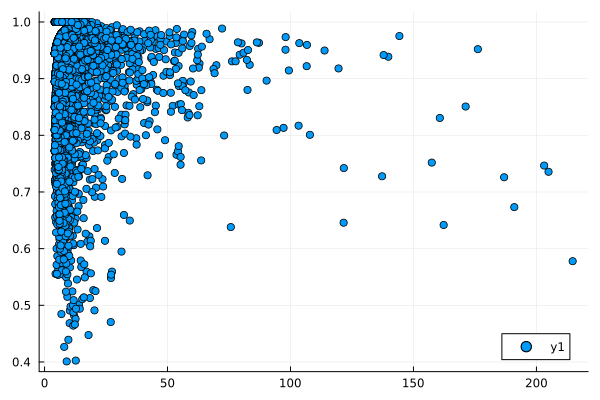

In [54]:
idx = df.area .> 16
idx = df.circularity .<= 1 .&& idx
Plots.scatter(df.area[idx].^0.5, df.solidity[idx])

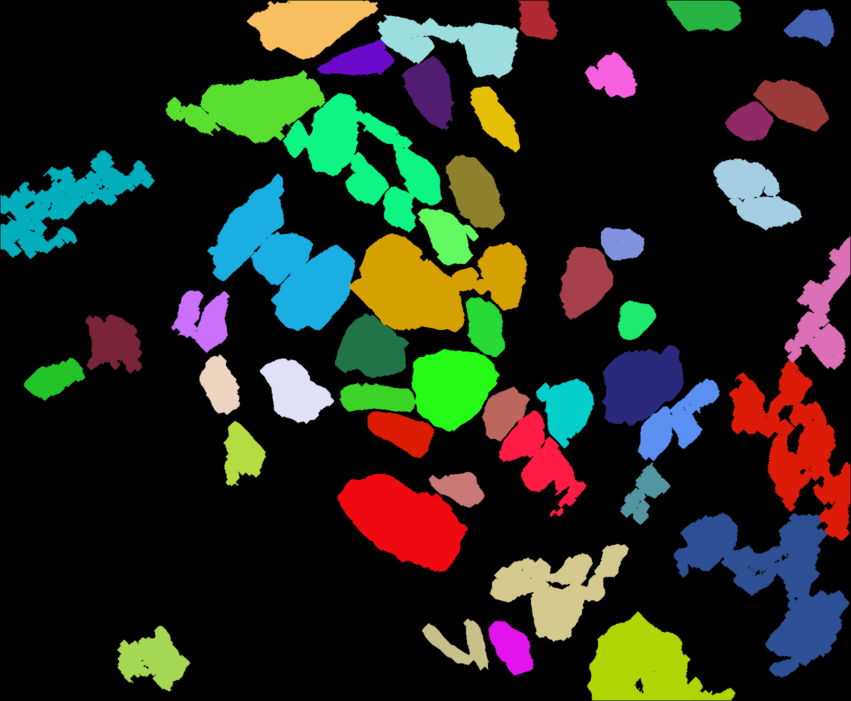

In [42]:
view_seg_random(SegmentedImage(img, test.intermediate[1]))

In [ ]:
dist = distance_transform(feature_transform(.!binary_floes))
   

Final cleanup from EB paper: remove objects with mean brightness less than 150/255

In [16]:
df = regionprops_table(test; properties=[:label, :area]);

LoadError: UndefVarError: `test` not defined in `Main`
Suggestion: add an appropriate import or assignment. This global was declared but not assigned.
Hint: a global variable of this name also exists in Pkg.

In [17]:
floe_mask = Gray.(view_seg(SegmentedImage(Gray.(red.(img)), test)) .> 150/255)
test[floe_mask .== 0] .= 0
segmented = SegmentedImage(img, test)
view_seg_random(segmented)

LoadError: UndefVarError: `img` not defined in `Main`
Suggestion: add an appropriate import or assignment. This global was declared but not assigned.

In [18]:
segmented

LoadError: UndefVarError: `segmented` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [19]:
@time begin
    test2 = dist_morph_split(binary_img .> 0)
end

LoadError: UndefVarError: `binary_img` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [20]:
view_seg_random(SegmentedImage(img, label_components(test2)))

LoadError: UndefVarError: `img` not defined in `Main`
Suggestion: add an appropriate import or assignment. This global was declared but not assigned.

In [21]:
# ebseg python code
import IceFloeTracker.Morphology: fill_holes

function erode_expand_buckley2024(
        gray_img, # image to use in the watershed transformation
        binary_img; # bitmatrix where ice is marked true
        itmin=1, # minimum number of iterations
        itmax=8, # maximum number of iterations
        step=1, # spacing between iterations
        strel=strel_diamond((3,3)),
        minimum_area=16,
        save_figs=true
        )

    input = copy(binary_img)
    input_no = copy(binary_img)
    
    output = zeros(Int64, size(binary_img))
    label_offset = 0
    
    for (r, iters) in enumerate(itmax:-step:itmin)
        eroded_ice_mask = copy(binary_img)
        foreach(_ -> erode!(eroded_ice_mask, copy(eroded_ice_mask), strel), 1:iters)
        fill_holes!(eroded_ice_mask, copy(eroded_ice_mask), strel_diamond((3,3)))

        markers = label_components(eroded_ice_mask)
        remove_small_segments!(markers, minimum_area)
        markers .+= 1
        
        dilated_ice_mask = copy(eroded_ice_mask)
        foreach(_ -> dilate!(dilated_ice_mask, copy(dilated_ice_mask), strel), 1:iters)
        
        unknown = copy(dilated_ice_mask)
        unknown[eroded_ice_mask .> 0] .= 0
        markers[unknown .> 0] .= 0
        
        # Dilating the markers replaces values with the maximum in the neighborhood,
        # which can have surprising results with randomly-labeled data.
        foreach(_ -> dilate!(markers, copy(markers), strel), 1:iters)
            
        # Use the watershed transformation to recover some detail of floe edges
        watershed_labels = labels_map(watershed(complement.(gray_img), markers))
        watershed_labels .-= 1
        
        # Set anything originally classified as water to background
        watershed_labels[binary_img .== 0] .= 0
        
        # Clear objects intersecting the land mask (TBD - no land in this image)

        # Clear objects where we've already got output labels
        watershed_labels[output .> 0] .= 0

        # Re-label since regions often are split up at this stage
        watershed_labels .= label_components(watershed_labels)
        
        # Remove small segments
        remove_small_segments!(watershed_labels, maximum([minimum_area, iters^4]))

        if save_figs
            fname = "identification_round_"*string(r)*".png"
            save(fname, view_seg_random(SegmentedImage(binary_img, watershed_labels)))
        end

        # Input for next stage:
        # backround in the watershed, positive in the ice mask, positive at beginning of round
        input .= (watershed_labels .== 0) .&& (input .> 0) .&& (binary_img .> 0)

        # Update the output
        new_label_mask = watershed_labels .> 0
        output[new_label_mask] .= watershed_labels[new_label_mask] .+ label_offset
        label_offset = maximum(output)
    end
    output .= label_components(output)
    
    # add min brightness step (TBD)
    
    return output
end

erode_expand_buckley2024 (generic function with 1 method)

In [22]:
@time begin
    test = erode_expand_buckley2024(Gray.(img),
        binary_img; strel=strel_diamond((3,3)), step=1, itmax=8);
end
view_seg_random(SegmentedImage(img, test))

LoadError: UndefVarError: `img` not defined in `Main`
Suggestion: add an appropriate import or assignment. This global was declared but not assigned.

Moving forward (and to comparison with the distance-transform-based method).

1. It is clear that large floes are not being sufficiently separated. However, the algorithm is reasonably fast, and we can also quickly identify shapes which are